In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) -- 
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [3]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

In [4]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random
from scipy.stats import norm

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import shutil
import itertools
from tqdm.auto import tqdm
from time import time, sleep

import lightgbm as lgb

from sklearn.calibration import CalibrationDisplay
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer

import warnings
warnings.simplefilter('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")
# plt.style.use('ggplot')

def seed_everything(seed: int):
    print(f"✓ Seed everything at {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

✓ Seed everything at 42


In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'figure.format': 'svg',
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [6]:
# plt.rcParams.keys()

In [7]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"data.csv")

## ========================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

Train shape: (699635, 23)
Test shape: (299844, 22)
Orig shape: (129880, 22)

Frame type: <class 'pandas.core.frame.DataFrame'>


In [8]:
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [9]:
def get_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        class_weights = opt
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights
    else:
        classes_ = np.unique(y_true)
        weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
        class_weights = dict(zip(classes_, weights_))
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights

print("- Helper Functions Ready -")

- Helper Functions Ready -


In [10]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [11]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [12]:
ID = 'id'
TARGET = 'satisfaction'
train[TARGET] = train[TARGET].map({False: 0, True: 1})

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object']).columns.tolist()
main_base_cols = cat_cols + num_cols

## --------------------------------------------------------------
combined = pd.concat([X, X_test])
str_convert = [c for c in cat_cols if c in main_base_cols]
for c in str_convert:
    combined[c] = pd.factorize(combined[c])[0]
    # combined[c] = combined[c].astype('category')

X = combined.iloc[:len(X)]
X_test = combined.iloc[-len(X_test):]
## --------------------------------------------------------------

print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('Class', 'Type of Travel', 'Gender'),
    ('Class', 'Type of Travel', 'Age'),
    ('Flight Distance', 'Departure/Arrival time convenient'),
]
def feature_engineering(df, fit=False):
    # Fill NaNs
    for col in cat_cols:
        df[col] = df[col].fillna("missing")
    for col in num_cols:
        df[col] = df[col].fillna(0.0)

    # Categorize numericals
    for col in num_cols:
        cat_name = f"{col}_cat_"
        if fit:
            codes, uniques = df[col].factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = df[col].map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    # Count encoding
    for col in cat_cols + ['Leg room service']:
        count_name = f"_{col}_count"
        if fit:
            count_map = df[col].value_counts()
            category_map[count_name] = count_map
        else:
            count_map = category_map[count_name]
        df[count_name] = df[col].map(count_map).fillna(0).astype('int32')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_test, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")

X      init shape: (699635, 21)
X_test init shape: (299844, 21) 

init len(cat_cols): 4
init len(num_cols): 17 

len(new_cat_cols): 20
len(new_num_cols): 5 

prep len(cat_cols): 24
prep len(num_cols): 22 

X      prep shape: (699635, 46)
X_test prep shape: (299844, 46) 



In [13]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 699635 entries, 0 to 699634
Data columns (total 46 columns):
 #   Column                                              Non-Null Count   Dtype   
---  ------                                              --------------   -----   
 0   Age                                                 699635 non-null  int64   
 1   Flight Distance                                     699635 non-null  int64   
 2   Inflight wifi service                               699635 non-null  int64   
 3   Departure/Arrival time convenient                   699635 non-null  int64   
 4   Ease of Online booking                              699635 non-null  int64   
 5   Gate location                                       699635 non-null  int64   
 6   Food and drink                                      699635 non-null  int64   
 7   Online boarding                                     699635 non-null  int64   
 8   Seat comfort                                        699635 

In [14]:
_ = [c for c in X.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print(f"Train shape {X.shape}")
X.head()

Train shape (699635, 46)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,Age_cat_,Flight Distance_cat_,Inflight wifi service_cat_,Departure/Arrival time convenient_cat_,Ease of Online booking_cat_,Gate location_cat_,Food and drink_cat_,Online boarding_cat_,Seat comfort_cat_,Inflight entertainment_cat_,On-board service_cat_,Leg room service_cat_,Baggage handling_cat_,Checkin service_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,Arrival Delay in Minutes_cat_,_Gender_count,_Customer Type_count,_Type of Travel_count,_Class_count,_Leg room service_count,Class_Type of Travel_Gender_,Class_Type of Travel_Age_,Flight Distance_Departure/Arrival time convenient_
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,347952,576990,202194,327404,204124,0,0,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,351683,576990,497441,342212,182369,1,1,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,0,0,2,2,2,0,2,1,2,1,2,2,2,2,0,2,1,0,0,347952,576990,202194,327404,131580,0,2,2
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,3,3,2,1,3,0,2,1,2,2,2,1,2,1,1,0,0,351683,576990,202194,327404,182369,2,3,3
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,1,0,4,4,2,0,3,2,1,1,3,1,1,0,1,0,2,1,0,347952,122645,497441,327404,204124,3,4,4


# Config

In [15]:
if "digit_cols" in globals():
    print("✓ digit_cols available!")
else:
    print("𝗫 digit_cols unavailable!")

𝗫 digit_cols unavailable!


In [16]:
X[str_convert] = X[str_convert].astype('category')
X_test[str_convert] = X_test[str_convert].astype('category')

In [17]:
## -- Set parameters --
LR = 0.01

core_params = {
    'n_estimators': 10_000,
    'metric': 'auc',
    'n_jobs': -1,
    'verbose': -1,
    'random_state': 42,
    'importance_type': 'gain',
    'feature_pre_filter': False,
    "device": "gpu" if torch.cuda.is_available() else "cpu",
}

bag_params = core_params | {
    'data_sample_strategy': "bagging",
    'learning_rate': LR,
    'max_depth': -1,
    'num_leaves': 127,
    'min_child_samples': 40,
    'subsample': 0.8,
    'colsample_bytree': 0.4,
    # 'reg_alpha': 0.001,
    'reg_lambda': 3.0,
    'max_bin': 1024,
}

gos_params = core_params | {
    'data_sample_strategy': "goss",
    'top_rate': 0.6,
    'other_rate': 0.15,
    'learning_rate': LR,
    'max_depth': -1, #
    'num_leaves': 127, #
    'min_child_samples': 40, # ⚡️
    # # 'subsample': 0.812763,
    'colsample_bytree': 0.4,
    'reg_alpha': 0.001,
    'reg_lambda': 2.0,
    'max_bin': 1024,
}

print("Catboost Parameters set!")

Catboost Parameters set!


# ML TRAINING

In [18]:
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True
    ES = 250 # 50, 250
    VERB = 500 # 100, 500

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = f'LGBMbag_mlp'
print(f"\n🚀 Training {model_name}({X.shape[1]}) with {FOLDS } Folds")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr = X.iloc[tr_idx].copy()
    X_val = X.iloc[val_idx].copy()
    y_tr = y.iloc[tr_idx]
    y_val = y.iloc[val_idx]
    X_tst = X_test.copy()

    # Target encoding
    if CFG.TE:
        cats_ = [c for c in cat_cols if c.endswith("_cat_")]
        te_cols = combo_names + cats_
        TE = skTE(target_type='binary', cv=5, smooth='auto', random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = [
            'Class_Type of Travel_Age_',
            'Flight Distance_Departure/Arrival time convenient_',
            'Flight Distance_cat_',
        ] + cats_
        X_tr  = X_tr.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}\n")
    print("#"*16)
    print(f"### Fold {fold}/{FOLDS} ...")
    print("#"*16)

    if fold == 1: display(X_tr.head(3))

    cat_feats = X_tr.select_dtypes(include=['category']).columns.tolist()

    # --------------------------------------------------------------------
    if 'bag' in model_name:
        use_params = bag_params.copy()
    else:
        use_params = gos_params.copy()

    seeder = 42 #+ (fold-1)
    use_params['random_state'] = seeder
    use_params['categorical_feature'] = cat_feats
    # --------------------------------------------------------------

    model = lgb.LGBMClassifier(**use_params)
    model.fit(
        X_tr, y_tr, 
        eval_set=[(X_val, y_val)], 
        callbacks=[lgb.early_stopping(stopping_rounds=CFG.ES), lgb.log_evaluation(period=CFG.VERB)]
    )

    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds

    fold_test_preds = model.predict_proba(X_tst)[:, 1]
    test_preds += fold_test_preds / FOLDS

    best_iter = model.best_iteration_
    best_iterations.append(best_iter)

    feat_importances.append(np.asarray(model.feature_importances_))
    # --------------------------------------------------------------
    fold_score = roc_auc_score(y_val, val_preds)
    fold_scores.append(fold_score)

    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} | AUC: {fold_score:.6f}{Style.RESET_ALL}", end=" | ")
    print(f"seed={seeder}, tree={best_iter}\n")
    # torch.cuda.empty_cache()

## Update model_name with final features
features_used = X_val.columns
model_name = model_name + f"({len(features_used)})"

## -- CV results --
fold_results = {}

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape}")
print(f"{'='*50}")

for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s:.6f} @ tree {t}")
    fold_results[f'fold_{i}'] = s

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

print("-"*50)
print(f"OOF score: {Fore.BLUE}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n")

del X_tr, X_val, y_tr, y_val, model


🚀 Training LGBMbag_mlp(46) with 5 Folds
train=(559708, 47), valid=(139927, 47)

################
### Fold 1/5 ...
################


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,_Gender_count,_Customer Type_count,_Type of Travel_count,_Class_count,_Leg room service_count,Class_Type of Travel_Gender_,TE_Class_Type of Travel_Gender_,TE_Class_Type of Travel_Age_,TE_Flight Distance_Departure/Arrival time convenient_,TE_Age_cat_,TE_Flight Distance_cat_,TE_Inflight wifi service_cat_,TE_Departure/Arrival time convenient_cat_,TE_Ease of Online booking_cat_,TE_Gate location_cat_,TE_Food and drink_cat_,TE_Online boarding_cat_,TE_Seat comfort_cat_,TE_Inflight entertainment_cat_,TE_On-board service_cat_,TE_Leg room service_cat_,TE_Baggage handling_cat_,TE_Checkin service_cat_,TE_Cleanliness_cat_,TE_Departure Delay in Minutes_cat_,TE_Arrival Delay in Minutes_cat_
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,347952,576990,202194,327404,204124,0,0.096311,0.089315,0.271375,0.304775,0.330480,0.622415,0.401785,0.556401,0.337127,0.172881,0.641942,0.173584,0.126571,0.290437,0.593544,0.482432,0.460545,0.153889,0.447987,0.452160
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,351683,576990,497441,342212,182369,1,0.737039,0.849818,0.446797,0.620894,0.304013,0.950461,0.437332,0.755381,0.623974,0.566352,0.641942,0.570381,0.671793,0.654929,0.614495,0.609373,0.470647,0.438631,0.447987,0.452160
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,351683,576990,202194,327404,182369,2,0.098711,0.092416,0.470847,0.100171,0.543498,0.276503,0.436209,0.320884,0.338052,0.406645,0.127023,0.185220,0.238261,0.541416,0.614074,0.213443,0.470495,0.438229,0.448014,0.452234


Training until validation scores don't improve for 250 rounds
[500]	valid_0's auc: 0.959668
[1000]	valid_0's auc: 0.960697
[1500]	valid_0's auc: 0.960835
[2000]	valid_0's auc: 0.960865
Early stopping, best iteration is:
[1987]	valid_0's auc: 0.96087
Fold 1 | AUC: 0.960870 | seed=42, tree=1987

################
### Fold 2/5 ...
################
Training until validation scores don't improve for 250 rounds
[500]	valid_0's auc: 0.958253
[1000]	valid_0's auc: 0.959274
[1500]	valid_0's auc: 0.959448
[2000]	valid_0's auc: 0.959499
[2500]	valid_0's auc: 0.959524
Early stopping, best iteration is:
[2514]	valid_0's auc: 0.959529
Fold 2 | AUC: 0.959529 | seed=42, tree=2514

################
### Fold 3/5 ...
################
Training until validation scores don't improve for 250 rounds
[500]	valid_0's auc: 0.959946
[1000]	valid_0's auc: 0.96096
[1500]	valid_0's auc: 0.96111
Early stopping, best iteration is:
[1543]	valid_0's auc: 0.961116
Fold 3 | AUC: 0.961116 | seed=42, tree=1543

#############

In [19]:
# ==================================================
# 5-FOLD CV: LGBMgos_mlp(47) | (559708, 47)
# ==================================================
#  • Fold 1 AUC: 0.960634 @ tree 310
#  • Fold 2 AUC: 0.959408 @ tree 381
#  • Fold 3 AUC: 0.961065 @ tree 211
#  • Fold 4 AUC: 0.960583 @ tree 313
#  • Fold 5 AUC: 0.960580 @ tree 248
# --------------------------------------------------
# OOF score: 0.96044
# AVG score: 0.960454 ± 0.000554
# --------------------------------------------------
# 2.94 mins

# ==================================================
# 5-FOLD CV: LGBMbag_mlp(47) | (559708, 47)
# ==================================================
#  • Fold 1 AUC: 0.960743 @ tree 384
#  • Fold 2 AUC: 0.959347 @ tree 325
#  • Fold 3 AUC: 0.961014 @ tree 296
#  • Fold 4 AUC: 0.960567 @ tree 304
#  • Fold 5 AUC: 0.960418 @ tree 269
# --------------------------------------------------
# OOF score: 0.960413
# AVG score: 0.960418 ± 0.000571
# --------------------------------------------------
# 2.76 mins

In [20]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
print(fold_df.to_string())

print("-"*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print("-"*25)

print(f"{tt:.2f} mins")

           score
fold_1  0.960870
fold_2  0.959529
fold_3  0.961116
fold_4  0.960664
fold_5  0.960667
-------------------------
LGBMbag_mlp(47)_960569
-------------------------
15.33 mins


In [21]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.244270
1,699636,0.896842
2,699637,0.937755
3,699638,0.062192
4,699639,0.045237
...,...,...
299839,999474,0.045064
299840,999475,0.035863
299841,999476,0.216361
299842,999477,0.025036


In [26]:
# !rm -r /kaggle/working

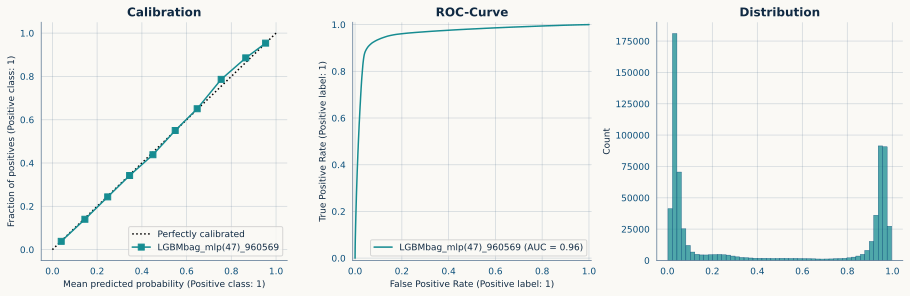

In [23]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

# for ax in axs:
#     ax.legend(loc='lower right')

plt.tight_layout(pad=0.2)
plt.show()

Total used features: 47



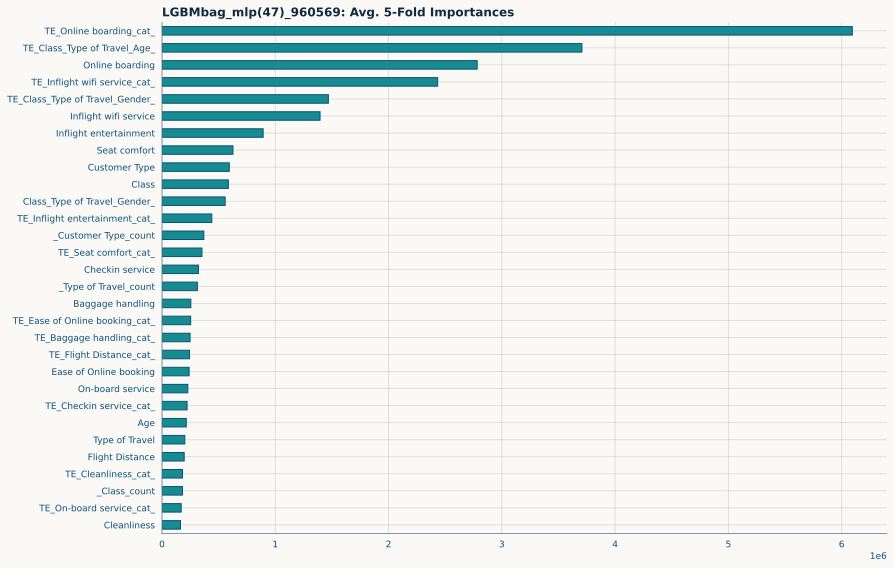

In [24]:
## -- Feature Importances --
imp_df = pd.Series(np.mean(feat_importances, axis=0), index=features_used).sort_values()
print(f"Total used features: {len(imp_df)}\n")

ax = imp_df[-30:].plot.barh(figsize=(12.5, 8))
ax.set_title(f"{n}: Avg. {FOLDS}-Fold Importances", loc='left')
ax.grid(True)

plt.tight_layout()
plt.show()